# Гордеев Иван ИУ9-71Б Вариант 6

## 1. Обучение с разными значениями lr

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from IPython.display import display

In [2]:
fmnist = fetch_openml(
    "Fashion-MNIST", version=1, as_frame=False,
    data_home=Path("data") / "scikit_learn", cache=True,
)
x = fmnist.data.astype(np.float32) / 255.0
y = LabelEncoder().fit_transform(fmnist.target).astype(np.int64)
del fmnist

SUBSAMPLE = 6000
rng = np.random.default_rng(42)
sub = rng.choice(len(x), size=SUBSAMPLE, replace=False)
x, y = x[sub], y[sub]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)
x_tr, x_val, y_tr, y_val = train_test_split(
    x_train, y_train, test_size=0.25, random_state=42, stratify=y_train
)

print("Обучение:", x_tr.shape)
print("Валидация:", x_val.shape)
print("Тест:", x_test.shape)

Обучение: (3600, 784)
Валидация: (1200, 784)
Тест: (1200, 784)


In [3]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_deriv(x):
    return x * (1 - x)

def sigmoid_complex_neuron(x, w, b):
    return sigmoid(x @ w + b)

def to_one_hot(y):
    return np.eye(10)[y]

def binary_cross_entropy(y_pred, y_true):
    eps = 1e-12
    y_pred = np.clip(y_pred, eps, 1 - eps)
    return -np.mean(np.sum(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred), axis=1))

In [4]:
class NeuralNetwork2Layers:
    def __init__(self, lr=0.01, n_iters=300, neuron_numb=128, seed=0, lr_schedule=None):
        rng = np.random.default_rng(seed)
        self.lr = lr
        self.n_iters = n_iters
        self.neuron_numb = neuron_numb

        lim0 = np.sqrt(6.0 / (784 + neuron_numb))
        lim1 = np.sqrt(6.0 / (neuron_numb + 10))
        self.w0 = rng.uniform(-lim0, lim0, (784, neuron_numb))
        self.w1 = rng.uniform(-lim1, lim1, (neuron_numb, 10))

        self.b0 = np.zeros(neuron_numb)
        self.b1 = np.zeros(10)

        self.lr_schedule = lr_schedule

    def get_loss(self, y_pred, y):
        return binary_cross_entropy(y_pred, y)

    def forward(self, x):
        layer0 = x
        layer1 = sigmoid_complex_neuron(layer0, self.w0, self.b0)
        layer2 = sigmoid_complex_neuron(layer1, self.w1, self.b1)
        return layer0, layer1, layer2

    def backward(self, layers, y):
        n = y.shape[0]
        layer0, layer1, layer2 = layers

        dz2 = (layer2 - y) / n 
        
        dLdw1 = layer1.T @ dz2
        dLdb1 = dz2.sum(axis=0)

        dz1 = (dz2 @ self.w1.T) * sigmoid_deriv(layer1)
        dLdw0 = layer0.T @ dz1
        dLdb0 = dz1.sum(axis=0)
        
        return dLdw0, dLdw1, dLdb0, dLdb1

    def step(self, grads):
        dLdw0, dLdw1, dLdb0, dLdb1 = grads
        self.w0 -= self.lr * dLdw0
        self.w1 -= self.lr * dLdw1
        self.b0 -= self.lr * dLdb0
        self.b1 -= self.lr * dLdb1

    def fit(self, x, y, batch_size=128):
        targets = to_one_hot(y)
        errors = []
        batch_rng = np.random.default_rng(42)

        global_step = 0 

        for epoch in range(self.n_iters):
            epoch_lrs = [] 
            indices = batch_rng.permutation(len(x))
            for start in range(0, len(x), batch_size):
                batch = indices[start:start + batch_size]

                if self.lr_schedule is not None:
                    self.lr = self.lr_schedule(global_step)
                epoch_lrs.append(self.lr)
                
                layers = self.forward(x[batch])
                grads = self.backward(layers, targets[batch])
                self.step(grads)
                global_step += 1 

            loss = self.get_loss(self.forward(x)[2], targets)
            errors.append(loss)

        return errors

    def predict(self, x):
        return np.argmax(self.forward(x)[2], axis=1)

    def evaluate(self, x, y):
        layer2 = self.forward(x)[2]
        loss = self.get_loss(layer2, to_one_hot(y))
        accuracy = np.mean(np.argmax(layer2, axis=1) == y)
        return loss, accuracy

Для всех запусков: SGD с mini-batch, 300 эпох, батч 128, 128 скрытых нейрона. Функция потерь BCE, в каждом слое функцией активацией является сигмоида

In [5]:
learning_rates = np.logspace(-5, 0, 8)
seeds = [0, 1, 2, 3, 4]
epochs = 300
batch_size = 128

rows = []
histories = {}

for seed in seeds:
    for lr in learning_rates:
        model = NeuralNetwork2Layers(lr=lr, n_iters=epochs, seed=seed)
        history = model.fit(x_tr, y_tr, batch_size=batch_size)
        histories[(lr, seed)] = history
        val_loss, val_acc = model.evaluate(x_val, y_val)
        test_loss, test_acc = model.evaluate(x_test, y_test)
        
        rows.append({"lr": lr, "seed": seed, "val_accuracy": val_acc, "test_accuracy": test_acc})

In [6]:
results = pd.DataFrame(rows)
display(results.round(6))

,lr,seed,val_accuracy,test_accuracy
0,0.000010,0,0.111667,0.109167
1,0.000052,0,0.285833,0.292500
2,0.000268,0,0.515833,0.544167
3,0.001389,0,0.687500,0.699167
4,0.007197,0,0.763333,0.780000
5,0.037276,0,0.825833,0.845833
6,0.193070,0,0.804167,0.827500
7,1.000000,0,0.827500,0.858333
8,0.000010,1,0.135833,0.137500
9,0.000052,1,0.301667,0.295000


In [7]:
val_summary = results.groupby("lr").agg(
    val_acc_mean=("val_accuracy", "mean"),
    val_acc_std =("val_accuracy", "std"),
)

best_lr = val_summary["val_acc_mean"].idxmax()
print(f"\nbest_lr по валидации: {best_lr:.6g}")
print(f"val accuracy: {val_summary.loc[best_lr, 'val_acc_mean']*100:.2f}%"
      f" +- {val_summary.loc[best_lr, 'val_acc_std']*100:.2f}")


best_lr по валидации: 1
val accuracy: 82.75% +- 0.54


#### ВЫВОД
Выполнены 40 запусков одной сети (5 сидов и для каждого 8 lr). На валидационной выборке лучше всего себя проявил lr = 1.

## 2. Кривые потерь, финальная точность, оптимальное окно

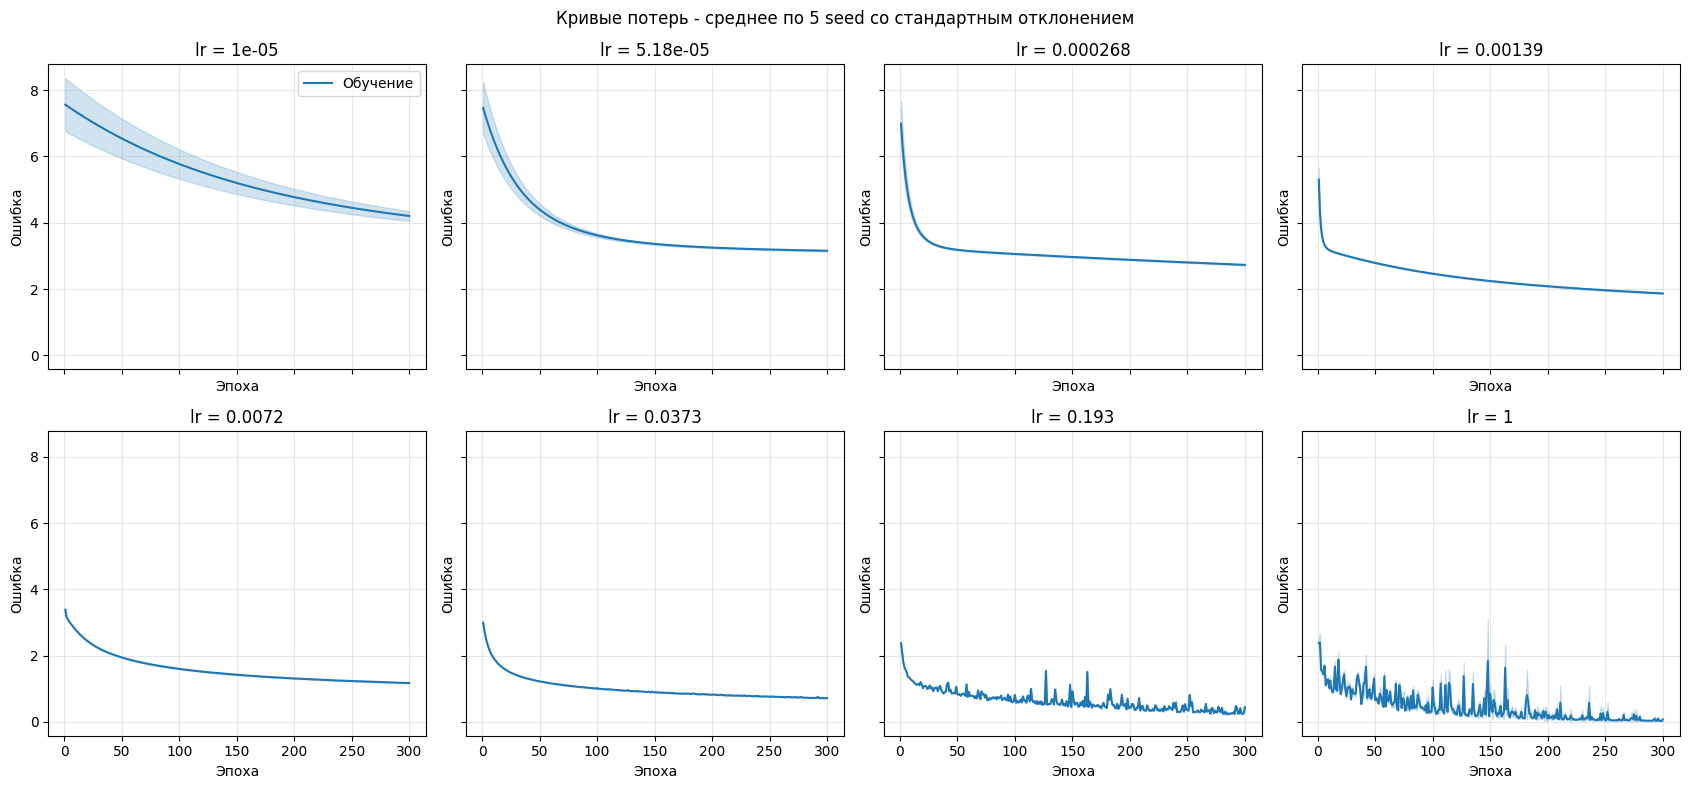

In [8]:
epoch_numbers = np.arange(1, epochs + 1)
fig, axes = plt.subplots(2, 4, figsize=(17, 8), sharex=True, sharey=True)
flat_axes = axes.flatten()

for i in range(len(learning_rates)):
    lr = learning_rates[i]
    axis = flat_axes[i]

    losses = np.array([histories[(lr, seed)] for seed in seeds])
    mean_loss = losses.mean(axis=0)
    std_loss = losses.std(axis=0, ddof=1)

    axis.plot(epoch_numbers, mean_loss, color="tab:blue", label="Обучение")
    axis.fill_between(
        epoch_numbers,
        np.maximum(0, mean_loss - std_loss),
        mean_loss + std_loss,
        color="tab:blue", alpha=0.2,
    )
    axis.set_title(f"lr = {lr:.3g}")
    axis.set_xlabel("Эпоха")
    axis.set_ylabel("Ошибка")
    axis.grid(alpha=0.3)

flat_axes[0].legend()
fig.suptitle("Кривые потерь - среднее по 5 seed со стандартным отклонением")
plt.tight_layout()
plt.show()

#### ВЫВОД
Для самых больших lr : 0,193 и 1 на графиках заметны колебания функции ошибок, что логично, ведь большем lr можно уйти по направлению слишком сильно. Графики выходят на плато


In [9]:
summary = results.groupby("lr").agg(
    test_acc_mean=("test_accuracy", "mean"),
    test_acc_std =("test_accuracy", "std"),
    val_acc_mean =("val_accuracy", "mean"),
    val_acc_std  =("val_accuracy", "std"),
)

display(summary.round(6))

,test_acc_mean,test_acc_std,val_acc_mean,val_acc_std
lr,,,,
0.000010,0.142833,0.044295,0.140333,0.043191
0.000052,0.313667,0.042572,0.317167,0.046277
0.000268,0.583000,0.024711,0.578833,0.038381
0.001389,0.710167,0.014086,0.695667,0.011109
0.007197,0.781500,0.006163,0.762000,0.002739
0.037276,0.846500,0.002157,0.821333,0.002801
0.193070,0.832500,0.005303,0.810500,0.005484
1.000000,0.854000,0.008131,0.827500,0.005433


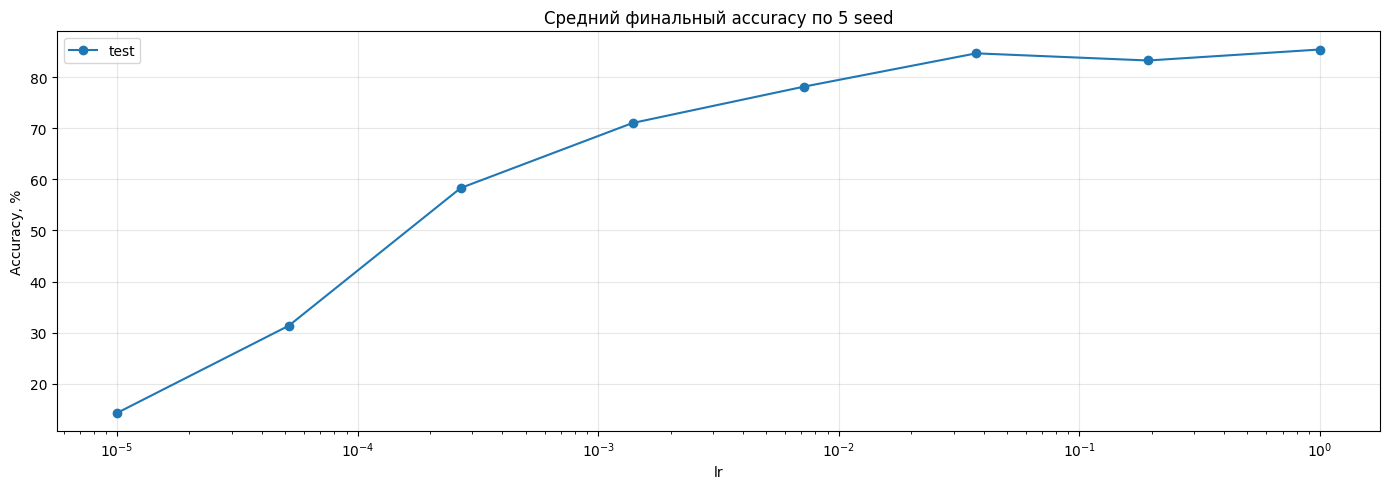

In [10]:
fig, ax = plt.subplots(1, 1, figsize=(14, 5))

ax.plot(summary.index, summary["test_acc_mean"] * 100,
        marker="o", label="test")

ax.set_xscale("log")
ax.set_xlabel("lr")
ax.set_ylabel("Accuracy, %")
ax.set_title("Средний финальный accuracy по 5 seed")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

#### ВЫВОД
С ростом lr accuracy монотонно возврастает, только при lr = 0,193 есть небольшой провал

### Оптимальное окно lr

Чтобы найти оптимальное окно был выбран 5% . То есть кроме лучшего lr оптимальными также будут считаться те lr, для которых accuracy модели отличается не более чем на 0.05 от accuracy, соответсвующего лучшему lr.

In [11]:
section = 0.05
best_mean = summary["val_acc_mean"].max()
window = summary[summary["val_acc_mean"] >= best_mean - section]
best_lr_idx = summary["val_acc_mean"].idxmax()
best = summary.loc[best_lr_idx]

print(f"Лучший lr по средней accuracy на валидации: {best_lr_idx:.3g}")
print("Подходящие значения сетки:", [f"{lr:.3g}" for lr in window.index])

Лучший lr по средней accuracy на валидации: 1
Подходящие значения сетки: ['0.0373', '0.193', '1']


#### Вывод
По валидационной выборке получено, что оптимальное окно для скорости обучения lr состоит из значений lr: (0,0373, 0.193, 1).
Тестовая выборка показала, что наилучший средний accuracy по 5 seed у модели с lr = 1 и равен 85.4 +- 0.8131

## 3. Расписания с изменением скорости обучения

In [12]:
lr0 = learning_rates[7]

sched_dfs = []
hist_sched = {}
schedule_fns = {}

def run_schedule(name, schedule_fn):
    rows, hist = [], {}
    for seed in seeds:
        model = NeuralNetwork2Layers(
            lr=lr0, n_iters=epochs, seed=seed, lr_schedule=schedule_fn,
        )
        
        hist[seed] = model.fit(x_tr, y_tr, batch_size=batch_size)

        vl_l, vl_a = model.evaluate(x_val, y_val)
        ts_l, ts_a = model.evaluate(x_test, y_test)
        rows.append({
            "schedule": name, "seed": seed,
            "val_loss": vl_l, "test_loss": ts_l,
            "val_acc": vl_a, "test_acc": ts_a,
        })

    df = pd.DataFrame(rows)
    sched_dfs.append(df)
    hist_sched[name] = hist
    schedule_fns[name] = schedule_fn
    print(f"[{name}] test acc = "
          f"{df['test_acc'].mean()*100:.2f}% +- {df['test_acc'].std()*100:.2f}")
    return df

In [13]:
step_period = 10
steps_max = epochs * int(np.ceil(len(x_tr) / batch_size)) 
lr_max = 1
lr_min = 0.0001

Понятно, что при lr = 1 accuracy достаточен, но можно попробовать улучшить его уменьшая lr, начиная с lr = 1

Для каждой модели число шагов обновления весов равно 300 * [3600 / 128] = 300 * 29 = 8700

#### 3.1 step decay

In [14]:
import math

def sched_step_decay(step):
    s = (step // step_period) * step_period
    return lr0 * 0.1 ** (s / steps_max)

run_schedule("step_decay", sched_step_decay)

[step_decay] test acc = 85.60% +- 0.57


,schedule,seed,val_loss,test_loss,val_acc,test_acc
0,step_decay,0,1.096311,0.926876,0.837500,0.857500
1,step_decay,1,1.116591,0.935309,0.825000,0.845833
2,step_decay,2,1.121050,0.946463,0.830833,0.858333
3,step_decay,3,1.099506,0.914379,0.825833,0.859167
4,step_decay,4,1.082388,0.935243,0.830000,0.859167


#### 3.2 exponentional decay

На калькулятор видно, что 0.99^8700 имеет порядок 10^-38 - слишком мало. А 0.999^8700 имеет порядок 10^-4, поэтому взял 0.999

In [15]:
def sched_exp_decay(step):
    return lr0 * 0.999 ** step
    #return lr0 * 0.9 ** (step / steps_max)

run_schedule("exp_decay", sched_exp_decay)

[exp_decay] test acc = 86.13% +- 0.30


,schedule,seed,val_loss,test_loss,val_acc,test_acc
0,exp_decay,0,0.877920,0.767147,0.833333,0.859167
1,exp_decay,1,0.887848,0.768642,0.830833,0.860833
2,exp_decay,2,0.880529,0.767425,0.829167,0.858333
3,exp_decay,3,0.871109,0.764974,0.835833,0.865833
4,exp_decay,4,0.871033,0.770976,0.832500,0.862500


#### 3.3 cosine annealing

Функция косинуса убывает от 0 до pi, поэтому если s < T, то lr будет убывать. А мы как раз берём T = steps_max

In [16]:
def sched_cosine_annealing(step):
    s = (step // step_period) * step_period
    T = steps_max
    return lr_min + (lr_max - lr_min) / 2.0 * (1.0 + math.cos(s / T * math.pi))
    
run_schedule("cosine_annealing", sched_cosine_annealing)

[cosine_annealing] test acc = 85.53% +- 0.25


,schedule,seed,val_loss,test_loss,val_acc,test_acc
0,cosine_annealing,0,1.156275,0.974271,0.830000,0.855000
1,cosine_annealing,1,1.157974,0.955025,0.826667,0.853333
2,cosine_annealing,2,1.166990,0.993888,0.834167,0.852500
3,cosine_annealing,3,1.148762,0.950312,0.835000,0.858333
4,cosine_annealing,4,1.127671,0.962937,0.836667,0.857500


#### 3.4 warmup + cosine
В начале lr будет расти, но в момент, когда step станет равен Twarm дальше могут случиться разные вещи. 
После того как step станет >= Twarm, то lr будет убывать до тех пор, пока s не превышает T (по свойству функции косинуса).
Если s не превысит T, то lr будет просто убывать до конца. Но если 
s превысит T, то lr будет возрастать и тогда будут возможны колебания.
Поэтому сделал 2 варианта

In [17]:
def sched_warmup_cosine1(step):
    Twarm = steps_max // 2

    if step < Twarm:
        return lr_min + (lr_max - lr_min) * (step / Twarm)

    T = Twarm
    s = ((step - Twarm) // step_period) * step_period
    return lr_min + (lr_max - lr_min) / 2.0 * (1.0 + math.cos(s / T * math.pi))

run_schedule("warmup_cosine1", sched_warmup_cosine1)

[warmup_cosine1] test acc = 85.37% +- 0.40


,schedule,seed,val_loss,test_loss,val_acc,test_acc
0,warmup_cosine1,0,1.190813,1.029773,0.835000,0.851667
1,warmup_cosine1,1,1.148142,1.006818,0.839167,0.854167
2,warmup_cosine1,2,1.186060,1.038234,0.833333,0.848333
3,warmup_cosine1,3,1.194072,1.009317,0.833333,0.859167
4,warmup_cosine1,4,1.197368,1.025605,0.834167,0.855000


In [18]:
def sched_warmup_cosine2(step):
    Twarm = int(0.05 * steps_max) 
    if step < Twarm:
        return lr_min + (lr_max - lr_min) * (step / Twarm)

    T = Twarm
    s = ((step - Twarm) // step_period) * step_period
    return lr_min + (lr_max - lr_min) / 2.0 * (1.0 + math.cos(s / T * math.pi))

run_schedule("warmup_cosine2", sched_warmup_cosine2)

[warmup_cosine2] test acc = 86.02% +- 0.31


,schedule,seed,val_loss,test_loss,val_acc,test_acc
0,warmup_cosine2,0,1.160811,0.988869,0.841667,0.860833
1,warmup_cosine2,1,1.154510,0.995243,0.836667,0.857500
2,warmup_cosine2,2,1.133060,0.970819,0.834167,0.860000
3,warmup_cosine2,3,1.165570,0.978863,0.835833,0.865000
4,warmup_cosine2,4,1.134287,0.976389,0.842500,0.857500


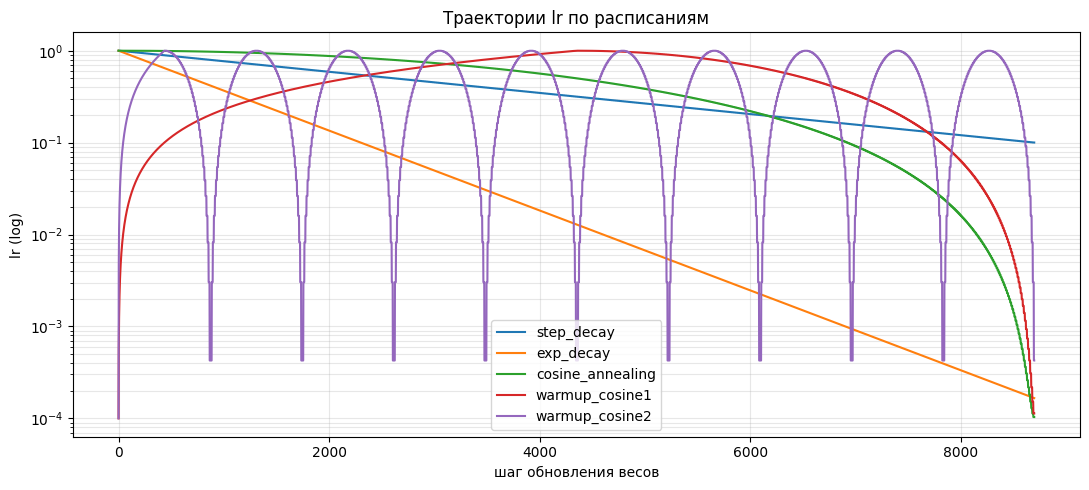

In [19]:
fig, ax = plt.subplots(figsize=(11, 5))
steps = np.arange(steps_max)
for name, fn in schedule_fns.items():
    lrs = np.array([fn(s) for s in steps])
    ax.plot(steps, lrs, label=name)
ax.set_yscale("log")
ax.set_xlabel("шаг обновления весов")
ax.set_ylabel("lr (log)")
ax.set_title("Траектории lr по расписаниям")
ax.grid(alpha=0.3, which="both")
ax.legend()
plt.tight_layout(); plt.show()

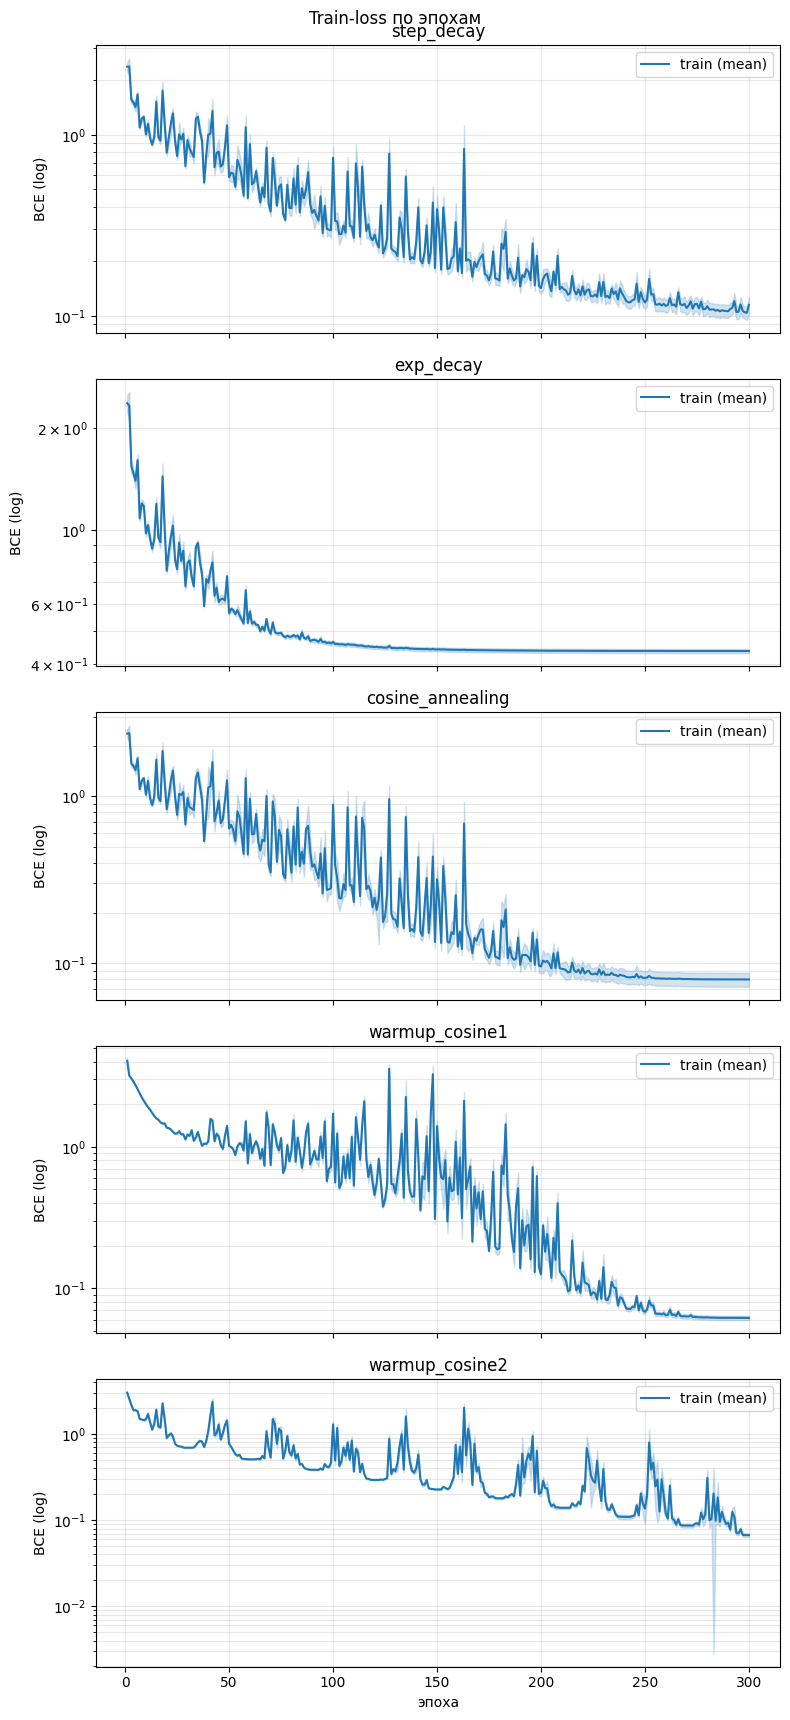

In [20]:
epoch_numbers = np.arange(1, epochs + 1)

n = len(schedule_fns)
fig, axes = plt.subplots(n, 1, figsize=(8, 3.5 * n), sharex=True)

for ax, name in zip(axes, schedule_fns):
    losses = np.array([hist_sched[name][s] for s in seeds])
    m  = losses.mean(0)
    sd = losses.std(0, ddof=1)

    ax.plot(epoch_numbers, m, color="tab:blue", label="train (mean)")
    ax.fill_between(
        epoch_numbers,
        np.maximum(m - sd, 1e-12),
        m + sd,
        color="tab:blue", alpha=0.2, label="",
    )

    ax.set_yscale("log")
    ax.set_title(name)
    ax.set_ylabel("BCE (log)")
    ax.grid(alpha=0.3, which="both")
    ax.legend(loc="upper right")

axes[-1].set_xlabel("эпоха")
fig.suptitle("Train-loss по эпохам")
plt.tight_layout()
plt.show()

In [21]:
all_df = pd.concat(sched_dfs, ignore_index=True)

sched_summary = all_df.groupby("schedule").agg(
    val_loss_mean =("val_loss", "mean"), val_loss_std =("val_loss", "std"),
    test_loss_mean =("test_loss", "mean"), test_loss_std =("test_loss", "std"),
    val_acc_mean =("val_acc", "mean"), val_acc_std =("val_acc", "std"),
    test_acc_mean =("test_acc", "mean"), test_acc_std =("test_acc", "std"),
)

In [22]:
sched_sorted = sched_summary.sort_values(
    by=["test_acc_mean", "test_acc_std"],
    ascending=[False, True],
)
best_name = sched_sorted.index[0]
best_row = sched_sorted.iloc[0]

display(sched_sorted[["test_acc_mean", "test_acc_std"]].head())

,test_acc_mean,test_acc_std
schedule,,
exp_decay,0.861333,0.002981
warmup_cosine2,0.860167,0.003084
step_decay,0.856000,0.005725
cosine_annealing,0.855333,0.002541
warmup_cosine1,0.853667,0.004023


#### ВЫВОД
Как и ожидалось график lr по шагам обновления весов для модели с расписаниями warmup_cosine2 оказался колеблющимся, 
причём на мой взгляд достаточно красивым. Для warmup_cosine1 как раз видим, что к середине обучения колебания функции ошибок очень сильны, ведь в эти моменты lr достигает своего пика(так как был warmup), а дальше убывает. Для cosine_annealing значение lr в конце обучения стало небольшим, как раз по этому график функции ошибок к концу перестал колебаться. У моделей с расписаниями exp_decay и step_decay функции ошибок к концу обучения уменьшаются и колебания слабеют.  

Модели с разными расписаниями показали высокие результаты, лучше всего себя проявила модель с расписанием exp_decay и accuracy = 86,1333 +- 0.2981. Модель без расписания с постоянным lr = 1 имела accuracy = 85.4 +- 0.8131, то есть модель стала лучше незначительно.

## 4. Большой шаг

/tmp/ipykernel_998862/572758259.py:2: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-x))


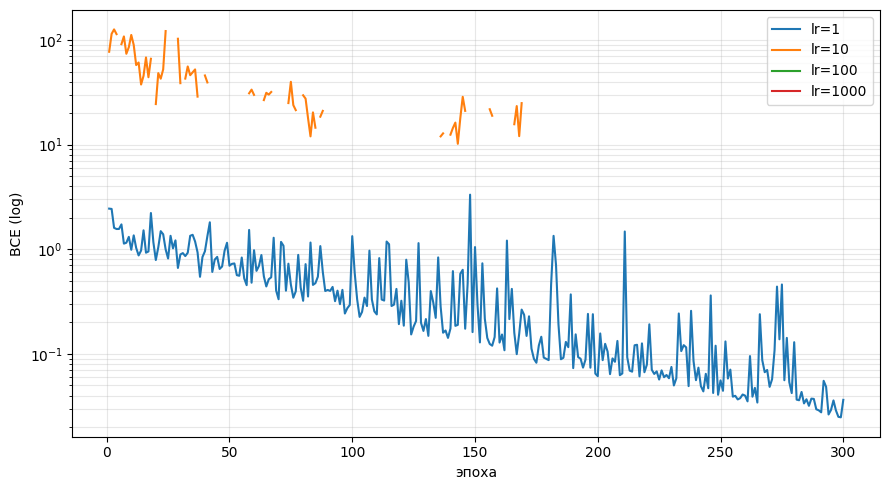

,lr,final_loss,n_inf,n_nan,test_acc
0,1,0.0364,0,0,0.8583
1,10,NaN,11,196,0.5525
2,100,NaN,0,300,0.0967
3,1000,NaN,0,300,0.0992


In [23]:
def bce_unclipped(y_pred, y_true):
    with np.errstate(divide="ignore", invalid="ignore"):
        return -np.mean(np.sum(y_true*np.log(y_pred) + (1-y_true)*np.log(1-y_pred), axis=1))

large_lrs = [1, 10, 100, 1000]
fig, ax = plt.subplots(figsize=(9, 5))
rows = []

for lr_val in large_lrs:
    model = NeuralNetwork2Layers(lr=lr_val, n_iters=epochs, seed=0)
    model.get_loss = bce_unclipped 
    h = np.array(model.fit(x_tr, y_tr, batch_size=batch_size))
    ax.plot(np.arange(1, epochs+1), np.where(np.isfinite(h), h, np.nan), label=f"lr={lr_val:g}")
    _, ts_acc = model.evaluate(x_test, y_test)
    rows.append({"lr": lr_val, "final_loss": h[-1],
                 "n_inf": int(np.isinf(h).sum()), "n_nan": int(np.isnan(h).sum()),
                 "test_acc": ts_acc})

ax.set_yscale("log"); ax.set_xlabel("эпоха"); ax.set_ylabel("BCE (log)")
ax.grid(alpha=0.3, which="both"); ax.legend()
plt.tight_layout(); plt.show()

display(pd.DataFrame(rows).round(4))

#### ВЫВОД
Для lr = 1 модель обучалась, при lr = 10 модель частично обучается, и затем BCE становится inf из-за log(0).
При lr=100 или 1000 модель не учится: потеря с первой же эпохи становится NaN.
Поскольку NaN в агрегации через np.mean доминирует над inf, средняя потеря становится NaN с первой же эпохи. (NaN это  0 * log(0), Inf это log(0))

## 5. Адаптивная подстройка

In [24]:
class NeuralNetwork2LayersAdaptive(NeuralNetwork2Layers):

    def fit(self, x, y, x_val=None, y_val=None, batch_size=128,
            patience=10, factor=0.5, min_lr=1e-6, threshold=1e-4):
        targets = to_one_hot(y)
        val_targets = to_one_hot(y_val) if x_val is not None else None

        errors, val_errors, lr_history = [], [], []
        batch_rng = np.random.default_rng(42)

        best_loss = np.inf
        epochs_no_improve = 0

        for epoch in range(self.n_iters):
            indices = batch_rng.permutation(len(x))
            for start in range(0, len(x), batch_size):
                batch  = indices[start:start + batch_size]
                layers = self.forward(x[batch])
                grads  = self.backward(layers, targets[batch])
                self.step(grads)

            train_loss = self.get_loss(self.forward(x)[2], targets)
            errors.append(train_loss)

            if x_val is not None:
                current_loss = self.get_loss(self.forward(x_val)[2], val_targets)
                val_errors.append(current_loss)
            else:
                current_loss = train_loss

            if current_loss < best_loss - threshold:
                best_loss = current_loss
                epochs_no_improve = 0
            else:
                epochs_no_improve += 1

            if epochs_no_improve >= patience and self.lr > min_lr:
                self.lr = max(self.lr * factor, min_lr)
                epochs_no_improve = 0

            lr_history.append(self.lr)

        return errors, val_errors, lr_history

In [25]:
seeds = [0, 1, 2, 3, 4]
epochs = 300
batch_size = 128
lr0 = 1.0
patience = 10
factor = 0.5
min_lr = 1e-4

fixed_hist, fixed_rows = {}, []
for seed in seeds:
    m = NeuralNetwork2Layers(lr=lr0, n_iters=epochs, seed=seed)
    h = m.fit(x_tr, y_tr, batch_size=batch_size)
    fixed_hist[seed] = h
    vl, va = m.evaluate(x_val, y_val)
    tl, ta = m.evaluate(x_test, y_test)
    fixed_rows.append({"mode": "fixed", "seed": seed, "val_loss": vl, "test_loss": tl, "val_acc": va, "test_acc": ta})



adapt_tr_hist, adapt_lr_hist, adapt_rows = {}, {}, []
for seed in seeds:
    m = NeuralNetwork2LayersAdaptive(lr=lr0, n_iters=epochs, seed=seed)
    tr_h, val_h, lr_h = m.fit(x_tr, y_tr, x_val=x_val, y_val=y_val,batch_size=batch_size, patience=patience, factor=factor, min_lr=min_lr)
    adapt_tr_hist[seed] = tr_h
    adapt_lr_hist[seed] = lr_h
    vl, va = m.evaluate(x_val, y_val)
    tl, ta = m.evaluate(x_test, y_test)
    adapt_rows.append({"mode": "adaptive", "seed": seed,"val_loss": vl, "test_loss": tl, "val_acc": va, "test_acc": ta})

all_df = pd.concat([pd.DataFrame(fixed_rows), pd.DataFrame(adapt_rows)],
                   ignore_index=True)

summary = all_df.groupby("mode").agg(
    val_loss_mean=("val_loss", "mean"), val_loss_std=("val_loss", "std"),
    test_loss_mean=("test_loss", "mean"), test_loss_std=("test_loss", "std"),
    val_acc_mean=("val_acc", "mean"), val_acc_std=("val_acc", "std"),
    test_acc_mean=("test_acc", "mean"), test_acc_std=("test_acc", "std"),
)
display(summary.round(4))

,val_loss_mean,val_loss_std,test_loss_mean,test_loss_std,val_acc_mean,val_acc_std,test_acc_mean,test_acc_std
mode,,,,,,,,
adaptive,0.9002,0.0245,0.7793,0.0101,0.8310,0.0031,0.8613,0.0016
fixed,1.4137,0.0321,1.2019,0.0464,0.8275,0.0054,0.8540,0.0081


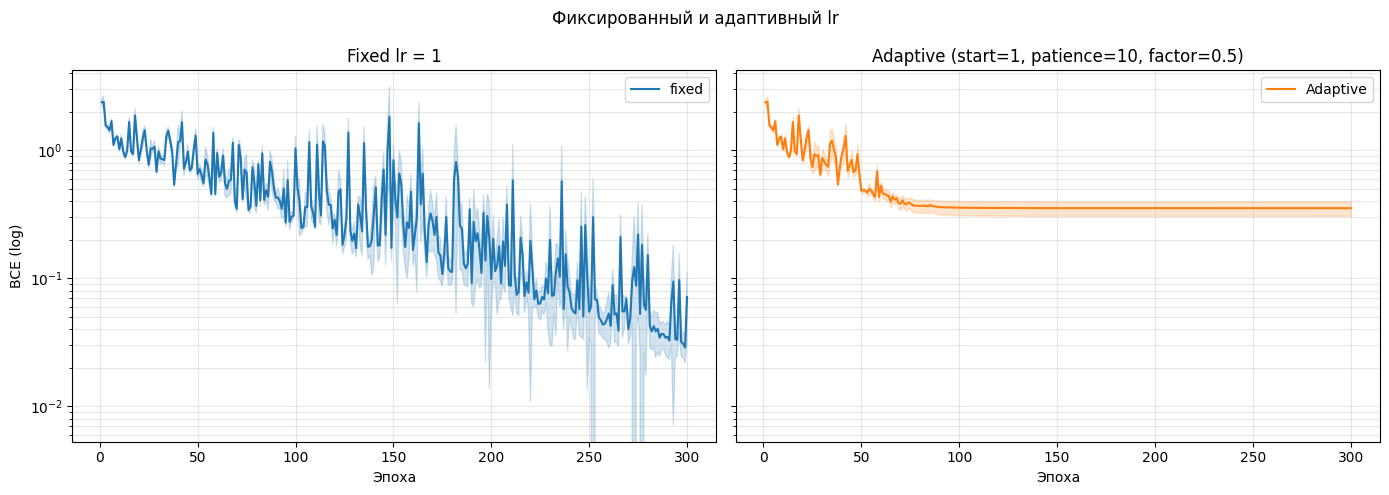

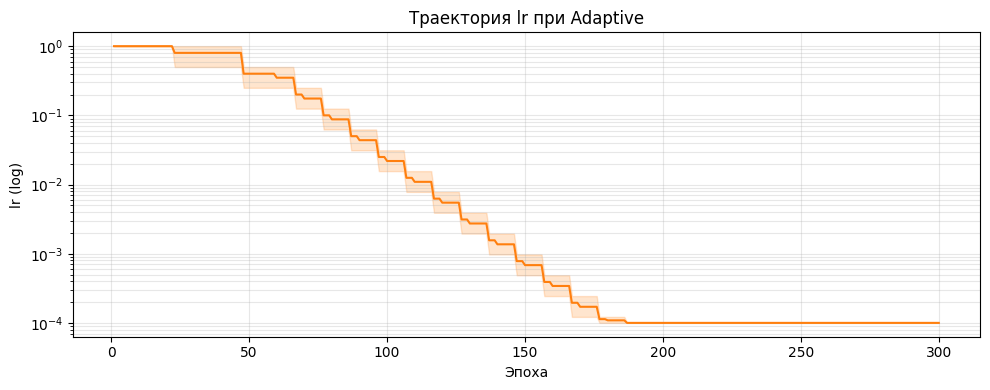

In [26]:
ep = np.arange(1, epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

fixed_losses  = np.array([fixed_hist[s] for s in seeds])
m, sd = fixed_losses.mean(0), fixed_losses.std(0, ddof=1)
axes[0].plot(ep, m, color="tab:blue", label="fixed")
axes[0].fill_between(ep, np.maximum(0, m - sd), m + sd, color="tab:blue", alpha=0.2)
axes[0].set_yscale("log"); axes[0].set_title(f"Fixed lr = {lr0:g}")
axes[0].set_xlabel("Эпоха"); axes[0].set_ylabel("BCE (log)")
axes[0].grid(alpha=0.3, which="both"); axes[0].legend()

adapt_losses = np.array([adapt_tr_hist[s] for s in seeds])
m, sd = adapt_losses.mean(0), adapt_losses.std(0, ddof=1)
axes[1].plot(ep, m, color="tab:orange", label="Adaptive")
axes[1].fill_between(ep, np.maximum(0, m - sd), m + sd, color="tab:orange", alpha=0.2)
axes[1].set_yscale("log")
axes[1].set_title(f"Adaptive (start={lr0:g}, patience={patience}, factor={factor})")
axes[1].set_xlabel("Эпоха")
axes[1].grid(alpha=0.3, which="both"); axes[1].legend()

fig.suptitle("Фиксированный и адаптивный lr")
plt.tight_layout(); plt.show()

lr_arr = np.array([adapt_lr_hist[s] for s in seeds])
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ep, lr_arr.mean(0), color="tab:orange")
ax.fill_between(ep, lr_arr.min(0), lr_arr.max(0), color="tab:orange", alpha=0.2)
ax.set_yscale("log"); ax.set_xlabel("Эпоха"); ax.set_ylabel("lr (log)")
ax.set_title("Траектория lr при Adaptive")
ax.grid(alpha=0.3, which="both"); plt.tight_layout(); plt.show()

#### ВЫВОД
При фиксированном lr график функции потерь всё время колеблется, а при использовании адаптивной подстройки после 100ой эпохи колебания не видны. Видно, что зависимость lr от эпохи действительно ступенчатая. Результаты показали, что для адаптивной настройки accuracy незначительно улучшился 86.13 +- 0.16

## Выводы

## 6. Контрольные вопросы
1)Почему warmup полезен для больших сетей?

В начале работы нейронной сети веса инициализируются случайным образом, и градиент указывает на нужно направление только в небольшой окрестности текущих весов, поэтому большой lr может привести к слишком резким изменениям параметров. В больших сетях изменение ранних слоёв меняет входы последующих слоёв, то есть влияние оказывается на всю сеть из-за чего функция ошибок может вырасти. А при warmup начальная скорость lr как раз небольшая.


2)Как lr связан с размером батча (эмпирическое правило)?

Пусть всего объектов в выборке n, размер батча - m, причём n = m * k. Рассмотрим произвольный вес wi. Пусть gi - средняя производная ошибки по wi на батче с номером i. (1 <= i <= k). Пусть все батчи пройдут через сеть независимо. Тогда можно сделать предположение, что вес wi изменится примерно на величину lr * (g1 + ... gk). (То есть теперь то они уже зависимо проходят через сеть). Теперь рассмотрим 1 батч, состоящий из k меньших батчей. Пусть для него другая скорость обучения lr2 .Тогда изменение веса wi будет lr2 * (g1 + ... gk)/k.
И если выбрать lr2/k = lr, то изменение будет таким же. То есть если увеличить размер батча в n раз, то lr также нужно увеличить примерно в n раз.



Для постоянного lr от 1e-5 до 1e-0 точность на валидационная и тестовой выборке монотонно росла за исключением lr = 0.193070.

По accuracy лучшим оказался lr = 1, оптимальным окном по accuracy на валидационной выборке с допуском 5% оказалось (0.0373, 0.193, 1)

Были реализованы и сравнены модели с расписаниями step decay, exponential decay, cosine annealing и warmup + cosine. По accuracy лучшим оказалось exponential decay с accuracy 86,1333 +- 0.2981. Фиксированный lr = 1 давал accuracy 85.4 +- 0.8131

При больших lr = 10, 100, 1000 обучение расходится, хотя при lr = 10 модель всё равно немного обучилась

Реализовано уменьшение lr при выходе валидационной потери на плато. При адаптивной подстройке accuracy немного стал лучше по сравнению с постоянным lr 
